In [1]:


import pandas as pd                  
import numpy as np                   
import matplotlib.pyplot as plt      
import seaborn as sns   

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Cell 2: Read the dataset
script_dir = Path.cwd()
file_path = r"C:\Users\User\Documents\GitHub\laptop-price-predictor\dataset\laptop_data.csv"
df = pd.read_csv(file_path)
print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (1303, 12)


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [3]:


print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types and missing-value overview:")
df.info()

print("\nSummary of numeric columns:")
display(df.describe())

Dataset dimensions: (1303, 12)

Column names:
['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price']

First five rows:


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080



Data types and missing-value overview:
<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1303 non-null   int64  
 1   Company           1303 non-null   str    
 2   TypeName          1303 non-null   str    
 3   Inches            1303 non-null   float64
 4   ScreenResolution  1303 non-null   str    
 5   Cpu               1303 non-null   str    
 6   Ram               1303 non-null   str    
 7   Memory            1303 non-null   str    
 8   Gpu               1303 non-null   str    
 9   OpSys             1303 non-null   str    
 10  Weight            1303 non-null   str    
 11  Price             1303 non-null   float64
dtypes: float64(2), int64(1), str(9)
memory usage: 122.3 KB

Summary of numeric columns:


,Unnamed: 0,Inches,Price
count,1303.00000,1303.000000,1303.000000
mean,651.00000,15.017191,59870.042910
std,376.28801,1.426304,37243.201786
min,0.00000,10.100000,9270.720000
25%,325.50000,14.000000,31914.720000
50%,651.00000,15.600000,52054.560000
75%,976.50000,15.600000,79274.246400
max,1302.00000,18.400000,324954.720000


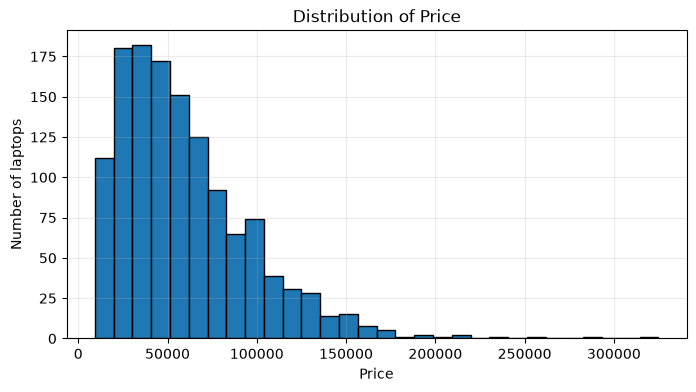

In [19]:


plt.figure(figsize=(8, 4))
plt.hist(df["Price"], bins=30, edgecolor="black")
plt.title("Distribution of Price")
plt.xlabel("Price")
plt.ylabel("Number of laptops")
plt.grid(alpha=0.25)
plt.show()

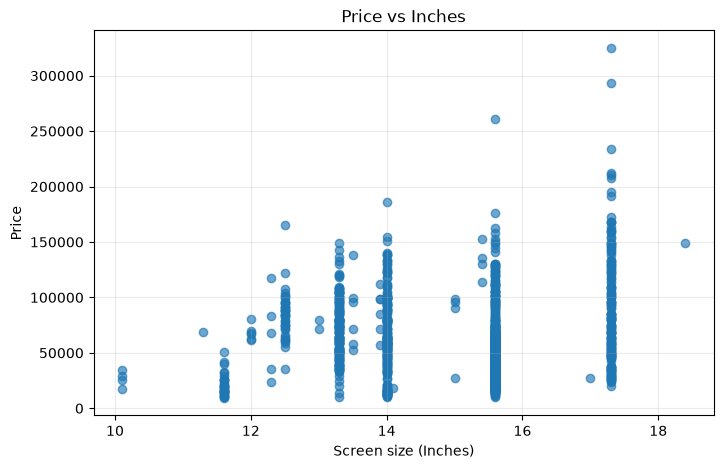

In [4]:


plt.figure(figsize=(8, 5))
plt.scatter(df["Inches"], df["Price"], alpha=0.65)
plt.title("Price vs Inches")
plt.xlabel("Screen size (Inches)")
plt.ylabel("Price")
plt.grid(alpha=0.25)
plt.show()

In [5]:


data = df.copy()
data = data.drop(columns=["Unnamed: 0"])

data["Ram"] = data["Ram"].str.replace("GB", "").astype(int)
data["Weight"] = data["Weight"].str.replace("kg", "").astype(float)

display(data[["Ram", "Weight", "Price"]].head())

,Ram,Weight,Price
0,8,1.37,71378.6832
1,8,1.34,47895.5232
2,8,1.86,30636.0000
3,16,1.83,135195.3360
4,8,1.37,96095.8080


In [6]:


data["Touchscreen"] = data["ScreenResolution"].str.contains("Touchscreen").astype(int)
data["IPS"] = data["ScreenResolution"].str.contains("IPS").astype(int)

resolution = data["ScreenResolution"].str.split().str[-1].str.split("x", expand=True).astype(int)
data["PPI"] = ((resolution[0] ** 2 + resolution[1] ** 2) ** 0.5) / data["Inches"]

display(data[["Touchscreen", "IPS", "PPI"]].head())

,Touchscreen,IPS,PPI
0,0,1,226.983005
1,0,0,127.677940
2,0,0,141.211998
3,0,1,220.534624
4,0,1,226.983005
